# Phase 6 — Purchase Prediction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay, classification_report)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
RANDOM_STATE = 42

PROC_DIR = Path('../data/processed')
MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(exist_ok=True)

df = pd.read_csv(PROC_DIR / 'olist_with_time_features.csv', parse_dates=['order_purchase_timestamp'])
print('Loaded shape:', df.shape)

Loaded shape: (42724, 48)


## Target variable & leakage-safe feature engineering

In [2]:
MAX_DATE = df['order_purchase_timestamp'].max()
CUTOFF_DATE = MAX_DATE - pd.Timedelta(days=90)
FUTURE_END = CUTOFF_DATE + pd.Timedelta(days=90)

print(f'Data range        : {df["order_purchase_timestamp"].min().date()} to {MAX_DATE.date()}')
print(f'Cutoff date        : {CUTOFF_DATE.date()}')
print(f'Future window       : {CUTOFF_DATE.date()} (exclusive) to {FUTURE_END.date()} (inclusive)')

order_level = df.drop_duplicates('order_id')[
    ['order_id', 'customer_unique_id', 'customer_state', 'order_purchase_timestamp',
     'payment_value', 'payment_type', 'review_score']
].copy()

past = order_level[order_level['order_purchase_timestamp'] <= CUTOFF_DATE].copy()
future = order_level[(order_level['order_purchase_timestamp'] > CUTOFF_DATE) &
                      (order_level['order_purchase_timestamp'] <= FUTURE_END)]

print(f'Past orders  : {len(past):,}  |  customers with history: {past["customer_unique_id"].nunique():,}')
print(f'Future orders: {len(future):,}  |  distinct repeat customers: {future["customer_unique_id"].nunique():,}')

Data range        : 2016-02-10 to 2018-12-08
Cutoff date        : 2018-09-09
Future window       : 2018-09-09 (exclusive) to 2018-12-08 (inclusive)
Past orders  : 33,024  |  customers with history: 32,441
Future orders: 4,594  |  distinct repeat customers: 4,569


In [3]:
items_past = df[df['order_purchase_timestamp'] <= CUTOFF_DATE]
items_per_order = items_past.groupby('order_id').size().rename('n_items')
past = past.merge(items_per_order, on='order_id')

REFERENCE_DATE = CUTOFF_DATE + pd.Timedelta(days=1)

customer_feat = past.groupby('customer_unique_id').agg(
    frequency=('order_id', 'nunique'),
    monetary_value=('payment_value', 'sum'),
    avg_basket_size=('n_items', 'mean'),
    last_purchase_date=('order_purchase_timestamp', 'max'),
    first_purchase_date=('order_purchase_timestamp', 'min'),
    avg_review_rating=('review_score', 'mean'),
    preferred_payment_method=('payment_type', lambda x: x.mode().iat[0] if not x.mode().empty else 'unknown'),
    customer_state=('customer_state', 'first'),
).reset_index()

customer_feat['avg_order_value'] = customer_feat['monetary_value'] / customer_feat['frequency']
customer_feat['recency_days'] = (REFERENCE_DATE - customer_feat['last_purchase_date']).dt.days
customer_feat['customer_tenure_days'] = (REFERENCE_DATE - customer_feat['first_purchase_date']).dt.days
customer_feat['avg_review_rating'] = customer_feat['avg_review_rating'].fillna(customer_feat['avg_review_rating'].median())

# Group rare states into 'other' to keep one-hot encoding manageable
top_states = customer_feat['customer_state'].value_counts().head(10).index
customer_feat['customer_state_grouped'] = np.where(
    customer_feat['customer_state'].isin(top_states), customer_feat['customer_state'], 'other'
)

print('customer_feat shape:', customer_feat.shape)
customer_feat.head()

customer_feat shape: (32441, 13)


,customer_unique_id,frequency,monetary_value,avg_basket_size,last_purchase_date,first_purchase_date,avg_review_rating,preferred_payment_method,customer_state,avg_order_value,recency_days,customer_tenure_days,customer_state_grouped
0,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,1.0,2018-07-05 11:11:00,2018-07-05 11:11:00,4.0,credit_card,SP,27.19,67,67,SP
1,0004bd2a26a76fe21f786e4fbd80607f,1,166.98,1.0,2018-05-04 19:33:00,2018-05-04 19:33:00,4.0,credit_card,SP,166.98,129,129,SP
2,0005e1862207bf6ccc02e4228effd9a0,1,150.12,1.0,2017-04-03 23:32:00,2017-04-03 23:32:00,4.0,credit_card,RJ,150.12,525,525,RJ
3,000a5ad9c4601d2bbdd9ed765d5213b3,1,91.28,1.0,2017-11-08 13:45:00,2017-11-08 13:45:00,4.0,credit_card,RS,91.28,306,306,RS
4,000c8bdb58a29e7115cfc257230fb21b,1,29.00,1.0,2017-12-12 22:53:00,2017-12-12 22:53:00,5.0,credit_card,MG,29.00,272,272,MG


In [4]:
repeat_customers = set(future['customer_unique_id'].unique())
customer_feat['repeat_purchase'] = customer_feat['customer_unique_id'].isin(repeat_customers).astype(int)

target_rate = customer_feat['repeat_purchase'].mean()
print(f'Repeat purchase rate: {target_rate:.2%}')
customer_feat['repeat_purchase'].value_counts()

Repeat purchase rate: 0.18%


repeat_purchase
0    32381
1       60
Name: count, dtype: int64

In [5]:
dataset = customer_feat[[
    'customer_unique_id', 'recency_days', 'frequency', 'monetary_value',
    'avg_order_value', 'avg_basket_size', 'customer_tenure_days', 'avg_review_rating',
    'preferred_payment_method', 'customer_state_grouped', 'repeat_purchase'
]].copy()

dataset.to_csv(PROC_DIR / 'purchase_prediction_dataset.csv', index=False)
print('Saved purchase_prediction_dataset.csv', dataset.shape)

Saved purchase_prediction_dataset.csv (32441, 11)


## Train/test split

In [6]:
numeric_features = ['recency_days', 'frequency', 'monetary_value', 'avg_order_value',
                    'avg_basket_size', 'customer_tenure_days', 'avg_review_rating']
categorical_features = ['preferred_payment_method', 'customer_state_grouped']

X = dataset[numeric_features + categorical_features]
y = dataset['repeat_purchase']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f'Train: {X_train.shape}, positive rate={y_train.mean():.2%}')
print(f'Test:  {X_test.shape}, positive rate={y_test.mean():.2%}')

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
])

Train: (25952, 9), positive rate=0.18%
Test:  (6489, 9), positive rate=0.18%


## Handling class imbalance — SMOTE & Class Weighting

In [7]:
def get_classifier(name, strategy, y_train):
    """Returns a fresh classifier instance configured for the given
    imbalance-handling strategy: 'none', 'class_weight', or 'smote'.
    For 'smote', the classifier itself uses no built-in weighting -
    the imbalance handling happens via the SMOTE pipeline step instead."""
    use_weight = (strategy == 'class_weight')

    if name == 'Logistic Regression':
        return LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                   class_weight='balanced' if use_weight else None)
    if name == 'Decision Tree':
        return DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=8,
                                       class_weight='balanced' if use_weight else None)
    if name == 'Random Forest':
        return RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1,
                                       class_weight='balanced' if use_weight else None)
    if name == 'XGBoost':
        spw = (y_train == 0).sum() / max((y_train == 1).sum(), 1) if use_weight else 1
        return XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss',
                              n_estimators=300, scale_pos_weight=spw)
    if name == 'LightGBM':
        return LGBMClassifier(random_state=RANDOM_STATE, n_estimators=300, verbose=-1,
                               class_weight='balanced' if use_weight else None)
    if name == 'CatBoost':
        return CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, iterations=300,
                                   auto_class_weights='Balanced' if use_weight else None)
    raise ValueError(name)

## Train 6 models × 3 imbalance strategies

Models: Logistic Regression, Decision Tree, Random Forest, XGBoost, LightGBM,
CatBoost. Each is trained three ways (baseline / class-weighted / SMOTE) so
§6 can compare which imbalance technique actually helps for each model —
it's not always the same answer.

In [8]:
MODEL_NAMES = ['Logistic Regression', 'Decision Tree', 'Random Forest',
               'XGBoost', 'LightGBM', 'CatBoost']
STRATEGIES = ['none', 'class_weight', 'smote']

results = []
fitted_pipelines = {}

for model_name in MODEL_NAMES:
    for strategy in STRATEGIES:
        clf = get_classifier(model_name, strategy, y_train)

        if strategy == 'smote':
            k_neighbors = min(5, (y_train == 1).sum() - 1, (y_train == 0).sum() - 1)
            if k_neighbors < 1:
                print(f'Skipping SMOTE for {model_name}: not enough minority samples')
                continue
            pipe = ImbPipeline([
                ('preprocess', preprocessor),
                ('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=k_neighbors)),
                ('clf', clf),
            ])
        else:
            pipe = Pipeline([
                ('preprocess', preprocessor),
                ('clf', clf),
            ])

        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)

        results.append({
            'model': model_name,
            'strategy': strategy,
            'accuracy': accuracy_score(y_test, y_pred),
            'precision': precision_score(y_test, y_pred, zero_division=0),
            'recall': recall_score(y_test, y_pred, zero_division=0),
            'f1': f1_score(y_test, y_pred, zero_division=0),
        })
        fitted_pipelines[(model_name, strategy)] = pipe
        print(f'{model_name:20s} | {strategy:12s} | done')

results_df = pd.DataFrame(results)
results_df

Logistic Regression  | none         | done
Logistic Regression  | class_weight | done
Logistic Regression  | smote        | done
Decision Tree        | none         | done
Decision Tree        | class_weight | done
Decision Tree        | smote        | done
Random Forest        | none         | done
Random Forest        | class_weight | done
Random Forest        | smote        | done
XGBoost              | none         | done
XGBoost              | class_weight | done
XGBoost              | smote        | done
LightGBM             | none         | done
LightGBM             | class_weight | done
LightGBM             | smote        | done
CatBoost             | none         | done
CatBoost             | class_weight | done
CatBoost             | smote        | done


,model,strategy,accuracy,precision,recall,f1
0,Logistic Regression,none,0.998151,0.000000,0.000000,0.000000
1,Logistic Regression,class_weight,0.661581,0.001825,0.333333,0.003630
2,Logistic Regression,smote,0.623671,0.001641,0.333333,0.003265
3,Decision Tree,none,0.998151,0.000000,0.000000,0.000000
4,Decision Tree,class_weight,0.856526,0.001086,0.083333,0.002144
5,Decision Tree,smote,0.796271,0.000000,0.000000,0.000000
6,Random Forest,none,0.998151,0.000000,0.000000,0.000000
7,Random Forest,class_weight,0.998151,0.000000,0.000000,0.000000
8,Random Forest,smote,0.993990,0.000000,0.000000,0.000000
9,XGBoost,none,0.998151,0.000000,0.000000,0.000000


## Evaluation — Accuracy, Precision, Recall, F1

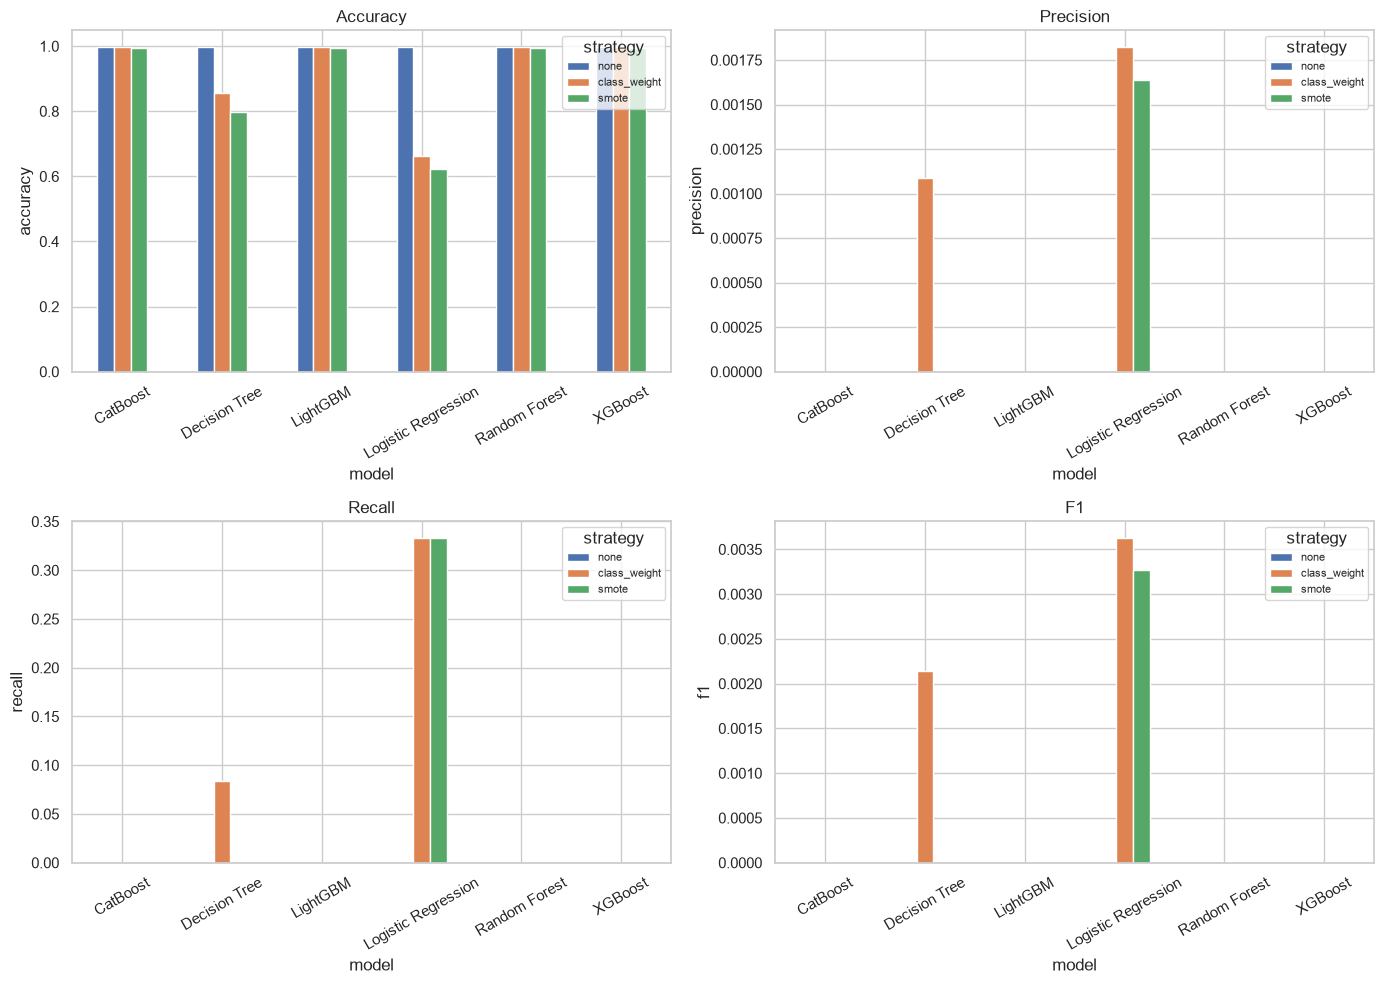

In [9]:
metrics = ['accuracy', 'precision', 'recall', 'f1']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, metric in zip(axes, metrics):
    pivot = results_df.pivot(index='model', columns='strategy', values=metric)
    pivot = pivot[['none', 'class_weight', 'smote']]
    pivot.plot(kind='bar', ax=ax, rot=30)
    ax.set_title(metric.capitalize())
    ax.set_ylabel(metric)
    ax.legend(title='strategy', fontsize=8)

plt.tight_layout()
plt.show()

**Reading these metrics for this business problem:** in a repeat-purchase
prediction used to trigger a retention campaign, missing a customer who would
have churned (a false negative — low **recall**) is usually more costly than
wasting a promo on someone who'd have returned anyway (a false positive — low
**precision**). If your business use case matches that, weight recall and F1
more heavily than raw accuracy when picking a final model — accuracy alone
can look deceptively good on an imbalanced target by mostly predicting the
majority class.

## Model comparison & best model selection

In [10]:
results_df_sorted = results_df.sort_values('f1', ascending=False).reset_index(drop=True)
results_df_sorted.style.background_gradient(subset=['accuracy', 'precision', 'recall', 'f1'], cmap='Greens')

,model,strategy,accuracy,precision,recall,f1
0,Logistic Regression,class_weight,0.661581,0.001825,0.333333,0.003630
1,Logistic Regression,smote,0.623671,0.001641,0.333333,0.003265
2,Decision Tree,class_weight,0.856526,0.001086,0.083333,0.002144
3,Logistic Regression,none,0.998151,0.000000,0.000000,0.000000
4,Decision Tree,none,0.998151,0.000000,0.000000,0.000000
5,Decision Tree,smote,0.796271,0.000000,0.000000,0.000000
6,Random Forest,none,0.998151,0.000000,0.000000,0.000000
7,Random Forest,class_weight,0.998151,0.000000,0.000000,0.000000
8,Random Forest,smote,0.993990,0.000000,0.000000,0.000000
9,XGBoost,none,0.998151,0.000000,0.000000,0.000000


Best model by F1: Logistic Regression (class_weight)
accuracy     0.661581
precision    0.001825
recall       0.333333
f1            0.00363
Name: 0, dtype: object

              precision    recall  f1-score   support

   No repeat       1.00      0.66      0.80      6477
      Repeat       0.00      0.33      0.00        12

    accuracy                           0.66      6489
   macro avg       0.50      0.50      0.40      6489
weighted avg       1.00      0.66      0.79      6489



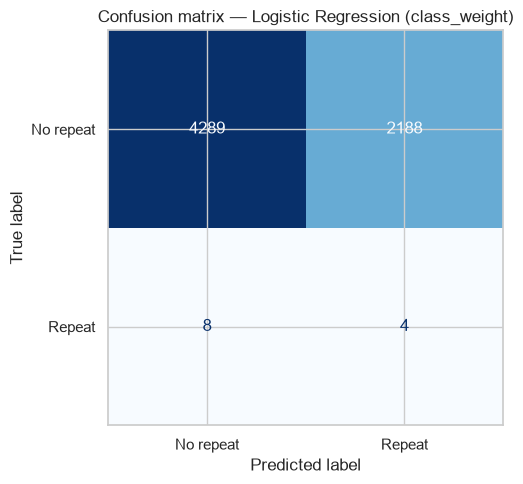

In [11]:
best_row = results_df_sorted.iloc[0]
best_model_name, best_strategy = best_row['model'], best_row['strategy']
best_pipeline = fitted_pipelines[(best_model_name, best_strategy)]

print(f'Best model by F1: {best_model_name} ({best_strategy})')
print(best_row[['accuracy', 'precision', 'recall', 'f1']])

y_pred_best = best_pipeline.predict(X_test)
print()
print(classification_report(y_test, y_pred_best, target_names=['No repeat', 'Repeat']))

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_best)
ConfusionMatrixDisplay(cm, display_labels=['No repeat', 'Repeat']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion matrix — {best_model_name} ({best_strategy})')
plt.tight_layout()
plt.show()

In [12]:
joblib.dump(best_pipeline, MODELS_DIR / 'purchase_prediction_model.pkl')
print(f"Saved best pipeline ({best_model_name}, {best_strategy}) to "
      f"{MODELS_DIR / 'purchase_prediction_model.pkl'}")

Saved best pipeline (Logistic Regression, class_weight) to ..\models\purchase_prediction_model.pkl
